# Previsão de Churn — Pipeline de Treinamento (Fase 1)

**Problema de negócio:** identificar clientes de uma operadora de telecom com alta chance de cancelar o contrato (*churn*), para que o time de retenção aja antes do cancelamento.

**Base:** [Telco Customer Churn (Kaggle / IBM)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn), 7.043 clientes e 21 colunas, salva em `data/telco_churn.csv`.

**Tipo de problema:** classificação binária (`Churn` = Yes/No).

Este notebook documenta e justifica cada decisão. O script `scripts/train.py` reproduz o mesmo pipeline e gera os artefatos usados pela API.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Caminho relativo: o notebook fica em notebooks/, os dados em data/
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "telco_churn.csv"
RANDOM_STATE = 42

## 1. Carregamento e análise exploratória

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


A coluna `TotalCharges` vem como texto porque clientes recém-contratados (`tenure = 0`) têm um espaço em branco no lugar do valor. Convertendo para número, esses casos viram `NaN` — é por isso que o pipeline precisa de **imputação de nulos**.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.isna().sum()[lambda s: s > 0]

TotalCharges    11
dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


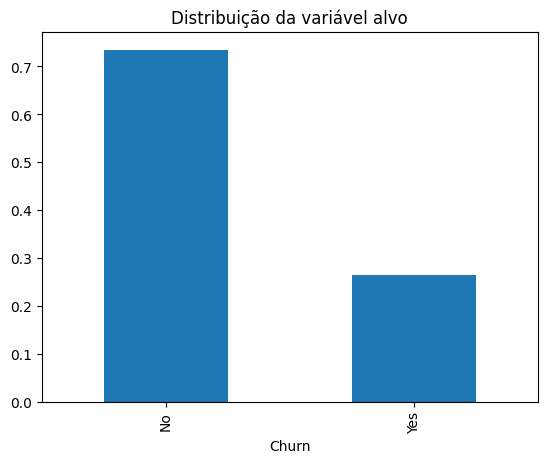

In [4]:
taxa = df["Churn"].value_counts(normalize=True).round(3)
print(taxa)
taxa.plot(kind="bar", title="Distribuição da variável alvo")
plt.show()

As classes são **desbalanceadas** (cerca de 1 em cada 4 clientes cancela). Por isso:
- a divisão dos dados será **estratificada**;
- a acurácia sozinha engana, então a seleção do modelo usará **ROC-AUC** e o relatório trará também **F1**.

In [5]:
df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean()).round(3)

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64

**Seleção de variáveis.** Ficamos com 12 colunas ligadas a tempo de casa, valores pagos, perfil e serviços contratados. `customerID` é só identificador e não entra no modelo. Menos colunas também deixam o contrato da API mais simples para quem consome.

In [6]:
NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
CATEGORICAL = ["Partner", "Dependents", "InternetService", "OnlineSecurity",
               "TechSupport", "Contract", "PaperlessBilling", "PaymentMethod"]

X = df[NUMERIC + CATEGORICAL]
y = (df["Churn"] == "Yes").astype(int)
X.shape

(7043, 12)

## 2. Divisão treino / validação / teste

- **70% treino**: ajusta os modelos.
- **15% validação**: compara os candidatos e escolhe o melhor.
- **15% teste**: usado **uma única vez** no final, para uma estimativa honesta do desempenho.

`stratify` mantém a proporção de churn igual nos três conjuntos; `random_state` fixo garante reprodutibilidade.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

for nome, alvo in [("treino", y_train), ("validação", y_val), ("teste", y_test)]:
    print(f"{nome:<10} {len(alvo):>5} linhas | churn = {alvo.mean():.3f}")

treino      4930 linhas | churn = 0.265
validação   1056 linhas | churn = 0.265
teste       1057 linhas | churn = 0.266
